In [16]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import json
import h5py

## Add the path to the DiscEvolution directory
sys.path.append('/Users/ben/Downloads/Planet Formation/Code/DiscEvolution')

## import DiscEvolution modules
from DiscEvolution.chemistry import SimpleCOMolAbund

## Method to Load in Data

In [17]:
## Method to read data from an HDF5 dataset or group

def read_hdf5_array(obj):
    """
    Read data from either an HDF5 dataset or an HDF5 group.
    """

    ## Normal case (the data are stored as one HDF5 dataset)
    if isinstance(obj, h5py.Dataset):
        return np.array(obj)

    ## Ragged case (the data are stored as a group)
    elif isinstance(obj, h5py.Group):
        values = []

        for key in sorted(obj.keys(), key = int):
            values.append(np.array(obj[key]))

        return values

    ## Raise an error if an unexpected HDF5 object is encountered
    else:
        raise TypeError(f"Unexpected HDF5 object type: {type(obj)}")

## Method to load data from an HDF5 file

def load_data(data_dir, config_dir):
    """
    Load a disc evolution output file (HDF5 only).

    Parameters:
        data_dir: Path to the HDF5 output file.
        config_dir: Path to the JSON config file used for the run.

    Returns:
        data: Dictionary containing the simulation output.
        config: Dictionary containing the simulation config file.
    """

    data = {}

    ## Load the configuration file
    with open(config_dir, "r") as f:
        config = json.load(f)

    ## Open the HDF5 file in read-only mode
    with h5py.File(data_dir, "r") as f:

        ## -----------------------
        ## General simulation data
        ## -----------------------

        general_keys = [
            "R",
            "t",
            "disk_Mdot_star",
            "disk_Mass",
            "Tc",
            "Sigc"]

        for key in general_keys:
            ## Only load the quantity if it exists in the file
            if key in f:
                data[key] = np.array(f[key])

        ## -----------------
        ## Scalar attributes
        ## -----------------

        scalar_attributes = [
            "alpha_SS",
            "psi_DW",
            "Mdot",
            "Mdisk",
            "Rd",
            "pla_eff",
            "f_plt",
            "complete",
            "aborted"]

        for key in scalar_attributes:
            ## Only load the attribute if it exists in the file
            if key in f.attrs:
                data[key] = f.attrs[key].item()

        ## Names of the chemical species (only written when chemistry is on)
        if "chem_species" in f.attrs:
            data["chem_species"] = [s.decode() if isinstance(s, bytes) else str(s) for s in f.attrs["chem_species"]]

        ## -------------
        ## Disk profiles
        ## -------------

        disk_keys = [
            "T",
            "time_snap",
            "Sigma_G",
            "Sigma_dust",
            "Sigma_pebbles",
            "Sigma_planetesimals",
            "Vdrift_grains",
            "Vdrift_pebbles",
            "St_grains",
            "St_pebbles",
            "St_planetesimals",
            "e_planetesimals",
            "i_planetesimals",
            "de2_dt",
            "di2_dt",
            "de2_dt_drag",
            "di2_dt_drag",
            "de2_dt_VS_embryo",
            "di2_dt_VS_embryo",
            "de2_dt_VS_pltsml",
            "di2_dt_VS_pltsml",
            "de2_dt_DF",
            "di2_dt_DF",
            "gas_chem",
            "ice_chem",
            "planetesimal_ice_chem"]

        for key in disk_keys:
            ## Only load the quantity if it exists in the file
            if key in f:
                data[key] = read_hdf5_array(f[key])

        ## -----------
        ## Planet data
        ## -----------

        if config["planets"]["include_planets"]:
            planet_keys = [
                "Mcs",
                "Mes",
                "Rp",
                "disk_Mdot_p",
                "Mdot_planetesimal",
                "Mdot_pebble_core",
                "Mdot_pebble_env",
                "Mdot_migration",
                "Mdot_gas",
                "M_iso_planetesimal",
                "M_iso_pebble",
                "X_cores",
                "X_envs",
                "f_env",
                "t_form"]

            for key in planet_keys:
                ## Only load the quantity if it exists in the file
                if key in f:
                    data[key] = read_hdf5_array(f[key])

    return data, config

## Bulk Composition Functions

In [ ]:
## Method to calculate the bulk metallicity of each planet

def bulk_metallicity(X_cores, X_envs, Mcs, Mes):
    """
    Calculate the bulk metallicity of each planet over time.
    This is the mass fraction of the whole planet (core + envelope) in heavy elements.

    Parameters:
        X_cores: Core mass abundances with shape (N_planets, N_species, N_times).
        X_envs: Envelope mass abundances with shape (N_planets, N_species, N_times).
        Mcs: Core masses with shape (N_planets, N_times).
        Mes: Envelope masses with shape (N_planets, N_times).

    Returns:
        Z: Bulk metallicity with shape (N_planets, N_times).
    """

    n_planets, n_spec, n_t = np.shape(X_cores)

    Z = np.zeros((n_planets, n_t))

    ## Calculate the time series for each planet in turn
    for p in range(n_planets):

        ## Load the core and envelope molecular abundances
        core = SimpleCOMolAbund(n_t)
        core.data[:] = X_cores[p]

        env = SimpleCOMolAbund(n_t)
        env.data[:] = X_envs[p]

        ## Mass of heavy elements in the core and envelope
        M_Z = core.total_abund * Mcs[p] + env.total_abund * Mes[p]

        Z[p] = M_Z / (Mcs[p] + Mes[p])

    return Z

## Method to calculate the envelope metallicity of each planet

def envelope_metallicity(X_envs):
    """
    Calculate the envelope metallicity of each planet over time.
    This is the mass fraction of the envelope in heavy elements (the rest is H/He).

    Parameters:
        X_envs: Envelope mass abundances with shape (N_planets, N_species, N_times).

    Returns:
        Z_env: Envelope metallicity with shape (N_planets, N_times).
    """

    n_planets, n_spec, n_t = np.shape(X_envs)

    Z_env = np.zeros((n_planets, n_t))

    ## Calculate the time series for each planet in turn
    for p in range(n_planets):

        ## Load the envelope molecular abundances
        env = SimpleCOMolAbund(n_t)
        env.data[:] = X_envs[p]

        Z_env[p] = env.total_abund

    return Z_env

## Method to calculate the total metal mass of each planet

def bulk_metal_mass(X_cores, X_envs, Mcs, Mes):
    """
    Calculate the total metal mass of each planet over time.
    This is the mass of heavy elements in the whole planet (core + envelope).

    Parameters:
        X_cores: Core mass abundances with shape (N_planets, N_species, N_times).
        X_envs: Envelope mass abundances with shape (N_planets, N_species, N_times).
        Mcs: Core masses with shape (N_planets, N_times).
        Mes: Envelope masses with shape (N_planets, N_times).

    Returns:
        M_Z: Total metal mass with shape (N_planets, N_times), in the same units as Mcs and Mes.
    """

    n_planets, n_spec, n_t = np.shape(X_cores)

    M_Z = np.zeros((n_planets, n_t))

    ## Calculate the time series for each planet in turn
    for p in range(n_planets):

        ## Load the core and envelope molecular abundances
        core = SimpleCOMolAbund(n_t)
        core.data[:] = X_cores[p]

        env = SimpleCOMolAbund(n_t)
        env.data[:] = X_envs[p]

        ## Mass of heavy elements in the core and envelope
        M_Z[p] = core.total_abund * Mcs[p] + env.total_abund * Mes[p]

    return M_Z

## Method to calculate the envelope metal mass of each planet

def envelope_metal_mass(X_envs, Mes):
    """
    Calculate the metal mass in the envelope of each planet over time.
    This is the mass of heavy elements in the envelope (the rest is H/He).

    Parameters:
        X_envs: Envelope mass abundances with shape (N_planets, N_species, N_times).
        Mes: Envelope masses with shape (N_planets, N_times).

    Returns:
        M_Z_env: Envelope metal mass with shape (N_planets, N_times), in the same units as Mes.
    """

    n_planets, n_spec, n_t = np.shape(X_envs)

    M_Z_env = np.zeros((n_planets, n_t))

    ## Calculate the time series for each planet in turn
    for p in range(n_planets):

        ## Load the envelope molecular abundances
        env = SimpleCOMolAbund(n_t)
        env.data[:] = X_envs[p]

        ## Mass of heavy elements in the envelope
        M_Z_env[p] = env.total_abund * Mes[p]

    return M_Z_env

## Method to calculate the volatile to refractory ratio of each planet

def bulk_volatile_refractory_ratio(X_cores, X_envs, Mcs, Mes):
    """
    Calculate the bulk volatile to refractory mass ratio of each planet over time.
    Volatiles are CO, CH4, CO2 and H2O and refractories are C-grain and Si-grain.

    Parameters:
        X_cores: Core mass abundances with shape (N_planets, N_species, N_times).
        X_envs: Envelope mass abundances with shape (N_planets, N_species, N_times).
        Mcs: Core masses with shape (N_planets, N_times).
        Mes: Envelope masses with shape (N_planets, N_times).

    Returns:
        VR: Volatile to refractory ratio with shape (N_planets, N_times).
            NaN wherever there are no refractories.
    """

    n_planets, n_spec, n_t = np.shape(X_cores)

    VR = np.zeros((n_planets, n_t))

    ## Calculate the time series for each planet in turn
    for p in range(n_planets):

        ## Load the core and envelope molecular abundances
        core = SimpleCOMolAbund(n_t)
        core.data[:] = X_cores[p]

        env = SimpleCOMolAbund(n_t)
        env.data[:] = X_envs[p]

        ## Mass of volatiles and refractories in the core and envelope
        volatiles = ((core["CO"] + core["CH4"] + core["CO2"] + core["H2O"]) * Mcs[p]
            + (env["CO"] + env["CH4"] + env["CO2"] + env["H2O"]) * Mes[p])

        refractories = ((core["C-grain"] + core["Si-grain"]) * Mcs[p]
            + (env["C-grain"] + env["Si-grain"]) * Mes[p])

        with np.errstate(invalid = "ignore", divide = "ignore"):
            VR_p = volatiles / refractories

        VR[p] = np.where(np.isfinite(VR_p), VR_p, np.nan)

    return VR

## Method to calculate the bulk water content of each planet

def bulk_water_content(X_cores, X_envs, Mcs, Mes):
    """
    Calculate the bulk water content of each planet over time.
    This is the mass fraction of the whole planet (core + envelope) that is H2O.

    Parameters:
        X_cores: Core mass abundances with shape (N_planets, N_species, N_times).
        X_envs: Envelope mass abundances with shape (N_planets, N_species, N_times).
        Mcs: Core masses with shape (N_planets, N_times).
        Mes: Envelope masses with shape (N_planets, N_times).

    Returns:
        f_H2O: Water mass fraction with shape (N_planets, N_times).
    """

    n_planets, n_spec, n_t = np.shape(X_cores)

    f_H2O = np.zeros((n_planets, n_t))

    ## Calculate the time series for each planet in turn
    for p in range(n_planets):

        ## Load the core and envelope molecular abundances
        core = SimpleCOMolAbund(n_t)
        core.data[:] = X_cores[p]

        env = SimpleCOMolAbund(n_t)
        env.data[:] = X_envs[p]

        ## Mass of water in the core and envelope
        M_H2O = core["H2O"] * Mcs[p] + env["H2O"] * Mes[p]

        f_H2O[p] = M_H2O / (Mcs[p] + Mes[p])

    return f_H2O

## Load in Data

In [19]:
## Load data and config file

data_dir = "/Users/ben/Downloads/Planet Formation/DiscEvolution Simulations/Output/popsynth_default_model.h5"
config_dir = "/Users/ben/Downloads/Planet Formation/DiscEvolution Simulations/Config/popsynth_default_config.json"

data, config = load_data(data_dir, config_dir)

In [20]:
## Disc profile
R = data["R"]

## Time data
t = data["t"]
t_interval = config["simulation"]["t_interval"]
n_times = len(t_interval)

# Planet chemistry data
X_cores = data["X_cores"]
X_envs = data["X_envs"]

# Planet data
Mcs = data["Mcs"]
Mes = data["Mes"]
Rp = data["Rp"]

## Global Plotting Style

In [21]:
## Matplotlib colors

color_blues = plt.cm.Blues(np.linspace(1, 0.4, n_times))
color_greys = plt.cm.Greys(np.linspace(1, 0.4, n_times))
color_greens = plt.cm.Greens(np.linspace(1, 0.4, n_times))
color_reds = plt.cm.Reds(np.linspace(1, 0.4, n_times))

## Global plot style

plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

## Method to bold the tick labels

def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

## Plot Planet Bulk Compositions

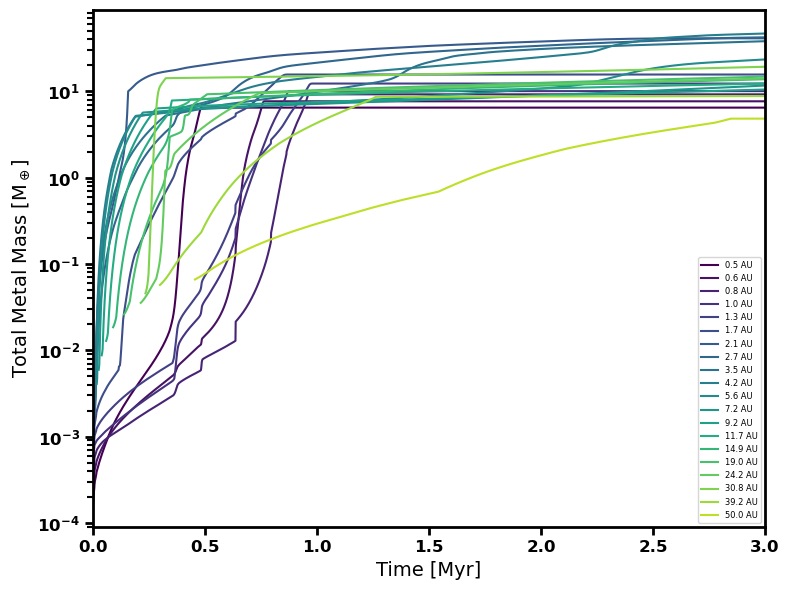

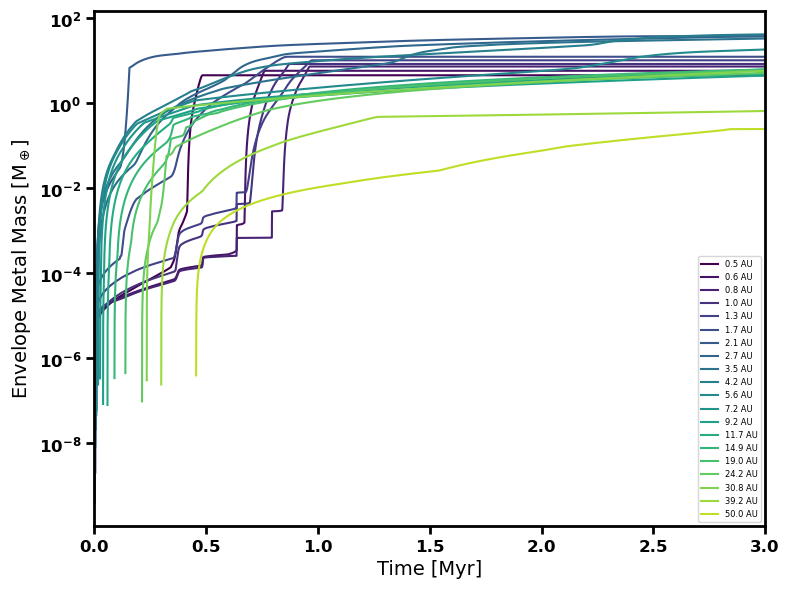

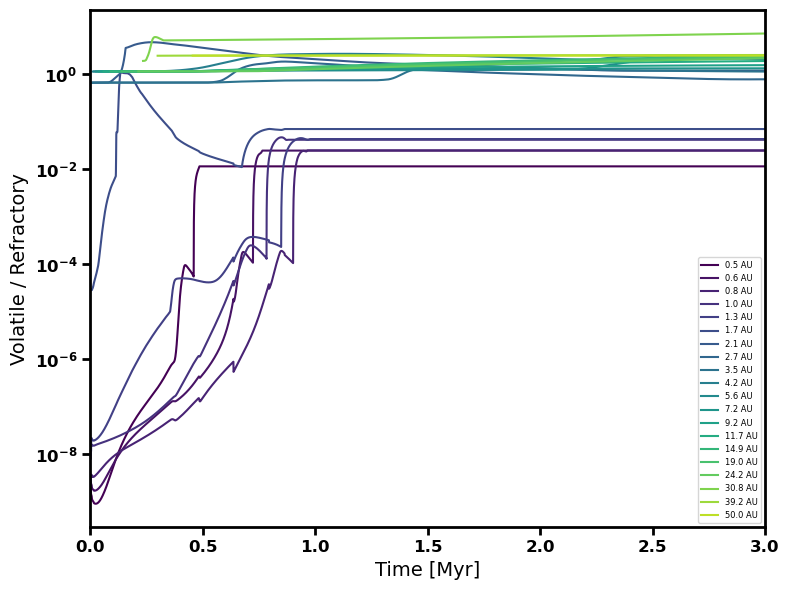

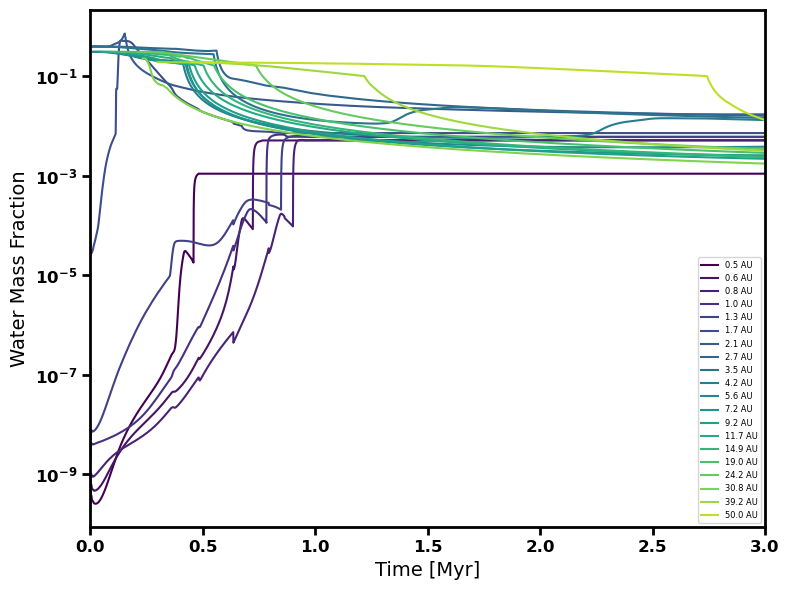

In [22]:
## Bulk composition of each planet over time

compositions = {
    r"Total Metal Mass [M$_\oplus$]": bulk_metal_mass(X_cores, X_envs, Mcs, Mes),
    r"Envelope Metal Mass [M$_\oplus$]": envelope_metal_mass(X_envs, Mes),
    "Volatile / Refractory": bulk_volatile_refractory_ratio(X_cores, X_envs, Mcs, Mes),
    "Water Mass Fraction": bulk_water_content(X_cores, X_envs, Mcs, Mes)}

n_planets = len(Rp)

## Starting position of each planet (its first recorded radius)

R_start = np.array([Rp[p][~np.isnan(Rp[p])][0] for p in range(n_planets)])

## Colour the planets in order of starting position (inner = dark, outer = light)

order = np.argsort(R_start)
planet_colors = np.zeros((n_planets, 4))
planet_colors[order] = plt.cm.viridis(np.linspace(0, 0.9, n_planets))

## y-axis scale of each composition

y_scale = {r"Total Metal Mass [M$_\oplus$]": 'log', r"Envelope Metal Mass [M$_\oplus$]": 'log',
    "Volatile / Refractory": 'log', "Water Mass Fraction": 'log'}

## One figure per composition, with every planet on the same axes

for composition in compositions:
    fig, ax = plt.subplots(figsize=(8, 6))

    for p in order:
        ax.plot(t / 1e6, compositions[composition][p], color = planet_colors[p], label = f'{round(R_start[p], 1)} AU')

    ax.set_yscale(y_scale[composition])
    ax.set_xlim(0, 3)
    ax.set_xlabel('Time [Myr]')
    ax.set_ylabel(composition)

    ax.legend(fontsize = 6)

    bold_ticks(ax)

    plt.tight_layout()

    plt.show()

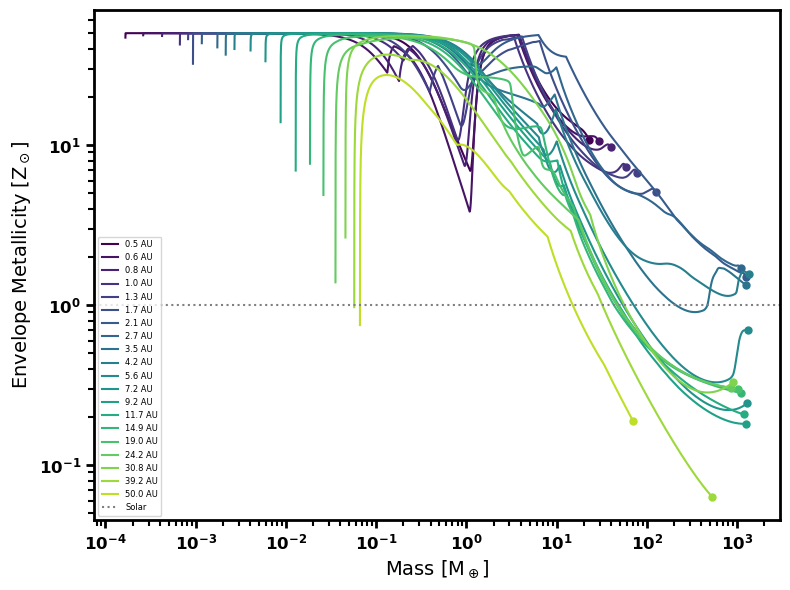

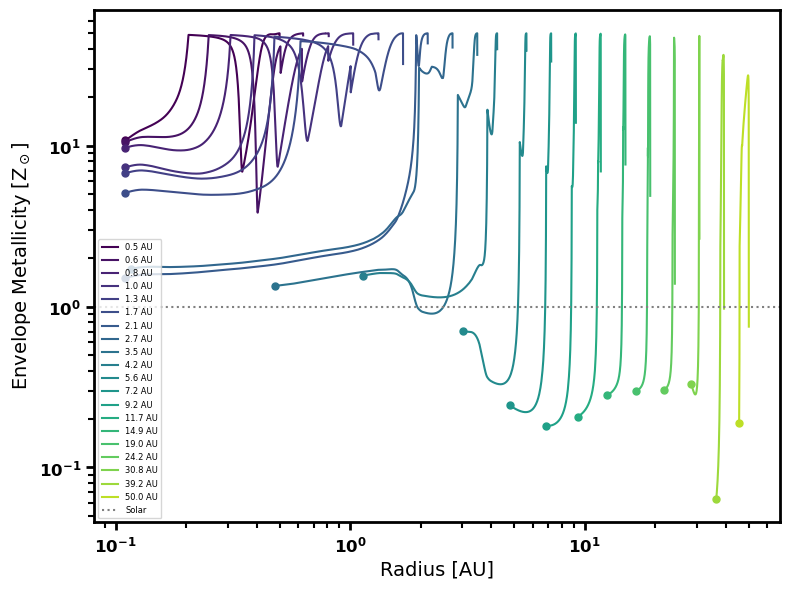

In [28]:
## Envelope metallicity of each planet against its envelope mass and its position in the disk

Z_solar = 0.02

## Envelope metallicity in solar units
Z_env = envelope_metallicity(X_envs) / Z_solar

tracks = {
    r"Mass [M$_\oplus$]": np.array(Mes + Mcs),
    "Radius [AU]": np.array(Rp)}

for track in tracks:
    fig, ax = plt.subplots(figsize=(8, 6))

    for p in order:
        ## Only plot times once the planet has an envelope (the envelope metallicity is 0 before then)
        has_env = np.array(Mes[p]) > 0

        x = tracks[track][p][has_env]
        y = Z_env[p][has_env]

        ax.plot(x, y, color = planet_colors[p], label = f'{round(R_start[p], 1)} AU')

        if len(x) > 0:
            ax.plot(x[-1], y[-1], 'o', color = planet_colors[p], markersize = 5)

    ## Solar reference value
    ax.axhline(1, color = '0.5', linestyle = ':', linewidth = 1.5, label = 'Solar')

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(track)
    ax.set_ylabel(r'Envelope Metallicity [Z$_\odot$]')

    ax.legend(fontsize = 6)

    bold_ticks(ax)

    plt.tight_layout()

    plt.show()